# 🧠 Transfer Learning — Feature Extraction
## Ejercicios 1 y 2 — un dataset real de Kaggle por ejercicio

| Ejercicio | Nivel | Dataset (Kaggle) | Modelo base | Enfoque |
|-----------|-------|------------------|-------------|---------|
| 1 | 🟢 Básico | Multi-class Weather (clima) | MobileNetV2 | Primer Feature Extraction + evaluación en test |
| 2 | 🟡 Intermedio | Fruit and Vegetable Image Recognition (36 clases) | EfficientNetB0 | EDA + Data Augmentation + métricas + feature maps |

Cada ejercicio descarga y carga **su propio dataset** al comenzar.

## ⚙️ 0. Configuración del entorno

In [1]:
# Instala las dependencias (si ya las tienes, no hace nada)
%pip install -q tensorflow scikit-learn seaborn pandas matplotlib kagglehub

In [1]:
import os, time, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
tf.random.set_seed(SEED)
np.random.seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
print(f"✅ TensorFlow {tf.__version__}")
print("🖥️ GPU:", [g.name for g in gpus] if gpus else
      "⚠️ No hay GPU — funcionará en CPU (más lento, pero funciona)")

✅ TensorFlow 2.21.0
🖥️ GPU: ['/physical_device:GPU:0']


---
# 🟢 Ejercicio 1 — Básico: MobileNetV2

**Objetivo:** primer contacto con Feature Extraction usando MobileNetV2 pre-entrenado en ImageNet. Es ligero (~2.2M parámetros), rápido y perfecto para empezar.

**Dataset:** [Multi-class Weather](https://www.kaggle.com/datasets/pratik2901/multiclass-weather-dataset) — imágenes de clima con pocas clases visualmente muy distintas, ideal para empezar.

### 1.1. Cargar y explorar el dataset

In [2]:
# Cargar Multi-class Weather desde Kaggle (se descarga automáticamente con kagglehub la primera vez)
import zipfile
from sklearn.model_selection import train_test_split

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
TRAIN_NAMES, VAL_NAMES, TEST_NAMES = {'train', 'training'}, {'val', 'valid', 'validation'}, {'test', 'testing'}

def has_images(d):
    return any(p.is_file() and p.suffix.lower() in IMG_EXTS for p in d.iterdir())

def find_class_root(root):
    # Kaggle suele anidar carpetas (dataset/dataset/clases): bajamos hasta la carpeta que contiene las clases
    root = pathlib.Path(root)
    while True:
        subdirs = [d for d in root.iterdir() if d.is_dir()]
        if len(subdirs) == 1 and not has_images(root):
            root = subdirs[0]
        else:
            return root

def list_images(class_root, class_names):
    paths, labels = [], []
    for idx, cname in enumerate(class_names):
        cdir = pathlib.Path(class_root) / cname
        if not cdir.is_dir():
            continue
        for p in cdir.rglob('*'):
            if p.is_file() and p.suffix.lower() in IMG_EXTS:
                paths.append(str(p)); labels.append(idx)
    return np.array(paths), np.array(labels, dtype='int64')

def pick(subdirs, names):
    return next((subdirs[n] for n in names if n in subdirs), None)

def make_ds(p, y):
    ds = tf.data.Dataset.from_tensor_slices((p, y.astype('int64')))
    def _load(path, label):
        img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        img.set_shape([None, None, 3])
        return img, label
    # ignore_errors: salta imágenes corruptas (frecuente en datasets de Kaggle)
    return ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).ignore_errors()

def load_dataset(cfg):
    '''Obtiene el dataset (Kaggle o carpeta local), detecta clases y splits, y devuelve los tf.data.Dataset.'''
    # ---- 1) Ruta del dataset
    if cfg['source'] == 'kaggle':
        import kagglehub
        try:
            data_dir = kagglehub.dataset_download(cfg['handle'])
        except Exception as e:
            raise RuntimeError(
                f"❌ No se pudo descargar '{cfg['handle']}' desde Kaggle.\n"
                "   Revisa que el identificador sea correcto (mira la URL del dataset en Kaggle) o descarga el .zip a mano\n"
                "   y usa source='folder', path=r'C:\\ruta\\al\\zip_o_carpeta'.") from e
        print(f"⬇️ Dataset de Kaggle listo: {cfg['handle']}")
    else:
        data_dir = str(cfg['path'])
        assert os.path.exists(data_dir), f"❌ No existe la ruta: {data_dir}"
        if data_dir.lower().endswith('.zip'):
            out_dir = pathlib.Path(data_dir).with_suffix('')
            if not out_dir.exists():
                print("📦 Descomprimiendo .zip ...")
                with zipfile.ZipFile(data_dir) as z:
                    z.extractall(out_dir)
            data_dir = str(out_dir)

    data_dir = pathlib.Path(data_dir)
    print("📂 Contenido:", sorted(d.name for d in data_dir.iterdir())[:10])
    if cfg.get('subfolder'):
        found = [d for d in data_dir.rglob('*') if d.is_dir() and d.name.lower() == cfg['subfolder'].lower()]
        assert found, f"❌ No se encontró la subcarpeta '{cfg['subfolder']}' dentro del dataset"
        data_dir = found[0]

    # ---- 2) Detectar clases y splits
    root = find_class_root(data_dir)
    subdirs = {d.name.lower(): d for d in root.iterdir() if d.is_dir()}
    train_dir, val_dir, test_dir = pick(subdirs, TRAIN_NAMES), pick(subdirs, VAL_NAMES), pick(subdirs, TEST_NAMES)

    if train_dir is not None and (val_dir is not None or test_dir is not None):
        print("🔎 Estructura detectada: ya viene separado en train/val/test")
        train_root = find_class_root(train_dir)
        class_names = sorted(d.name for d in train_root.iterdir() if d.is_dir())
        p_tr, y_tr = list_images(train_root, class_names)

        p_va = y_va = p_te = y_te = None
        if val_dir is not None:
            p_va, y_va = list_images(find_class_root(val_dir), class_names)
            if len(p_va) == 0: p_va = y_va = None
        if test_dir is not None:
            p_te, y_te = list_images(find_class_root(test_dir), class_names)
            if len(p_te) == 0: p_te = y_te = None

        if p_va is None:   # no hay val → se separa 15 % del train
            p_tr, p_va, y_tr, y_va = train_test_split(p_tr, y_tr, test_size=0.15, stratify=y_tr, random_state=SEED)
        if p_te is None:   # no hay test → se separa la mitad del val
            p_va, p_te, y_va, y_te = train_test_split(p_va, y_va, test_size=0.50, stratify=y_va, random_state=SEED)
    else:
        print("🔎 Estructura detectada: una carpeta por clase → split 70/15/15")
        class_names = sorted(d.name for d in root.iterdir() if d.is_dir())
        paths, labels = list_images(root, class_names)
        p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
        p_va, p_te, y_va, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

    assert len(class_names) >= 2 and len(p_tr) > 0, (
        "❌ No se detectaron clases/imágenes. Revisa la estructura de carpetas (puedes usar 'subfolder').")

    print(f"📦 Dataset: {cfg['name']}")
    print(f"🏷️ Clases ({len(class_names)}): {class_names if len(class_names) <= 20 else class_names[:20] + ['...']}")
    print(f"📊 Train: {len(p_tr):,} | Val: {len(p_va):,} | Test: {len(p_te):,}")

    return dict(
        train_raw=make_ds(p_tr, y_tr), val_raw=make_ds(p_va, y_va), test_raw=make_ds(p_te, y_te),
        CLASS_NAMES=class_names, NUM_CLASSES=len(class_names), DATASET_LABEL=cfg['name'],
        lab_train=y_tr, lab_val=y_va, lab_test=y_te,
        N_TRAIN=len(p_tr), N_VAL=len(p_va), N_TEST=len(p_te))

DS_INFO = {}
def use_dataset(cfg, k):
    d = load_dataset(cfg)
    globals().update(d)     # deja train_raw, val_raw, test_raw, CLASS_NAMES, NUM_CLASSES... listos para usar
    DS_INFO[k] = {n: d[n] for n in ('DATASET_LABEL', 'NUM_CLASSES', 'N_TRAIN', 'N_VAL', 'N_TEST')}

# ---------- Dataset del Ejercicio 1 ----------
# Si la descarga automática falla: baja el .zip de Kaggle a mano y usa
#   source='folder', path=r'C:\ruta\al\zip_o_carpeta'
DATASET_1 = dict(name='Multi-class Weather', source='kaggle',
                 handle='pratik2901/multiclass-weather-dataset', path=None, subfolder=None)
use_dataset(DATASET_1, 1)

Using Colab cache for faster access to the 'multiclass-weather-dataset' dataset.
⬇️ Dataset de Kaggle listo: pratik2901/multiclass-weather-dataset
📂 Contenido: ['Multi-class Weather Dataset']
🔎 Estructura detectada: una carpeta por clase → split 70/15/15
📦 Dataset: Multi-class Weather
🏷️ Clases (4): ['Cloudy', 'Rain', 'Shine', 'Sunrise']
📊 Train: 787 | Val: 169 | Test: 169


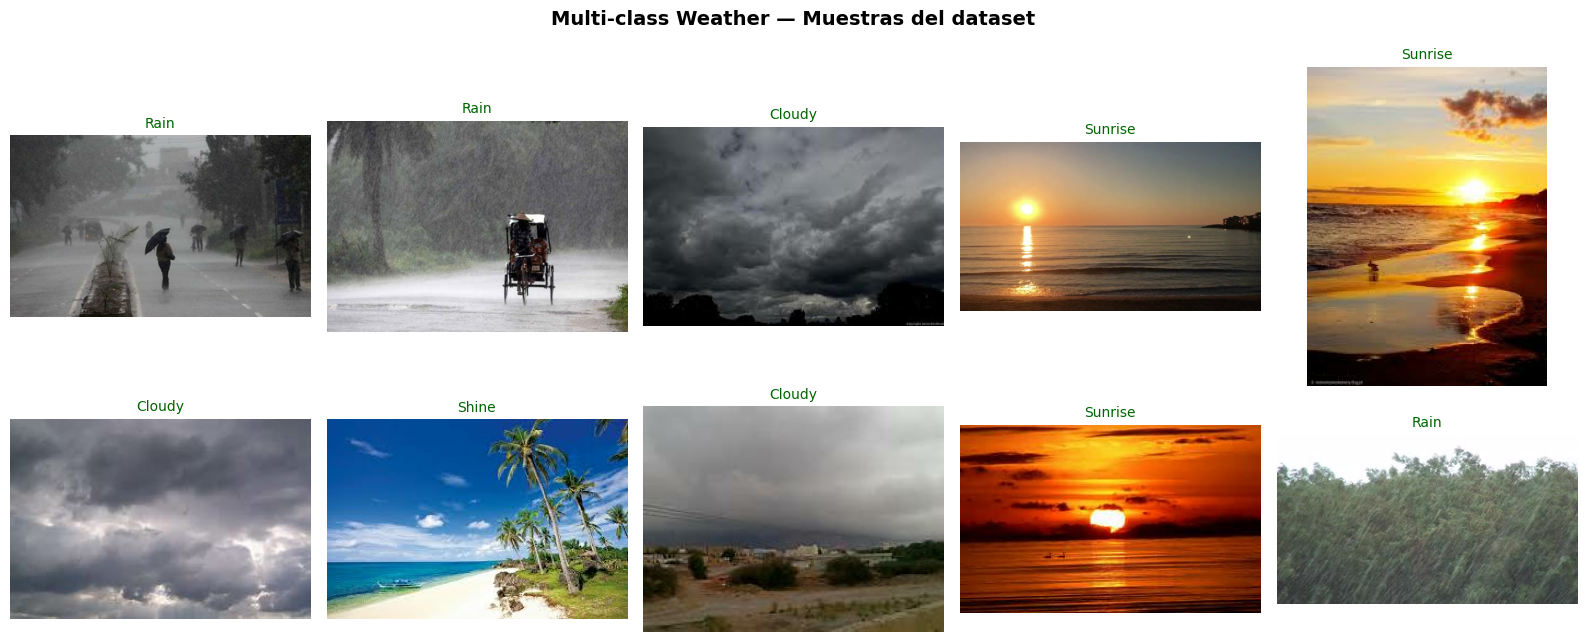

In [3]:
# Muestras aleatorias del dataset
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for i, (img, label) in enumerate(train_raw.shuffle(500, seed=SEED).take(10)):
    ax = axes[i // 5, i % 5]
    ax.imshow(img.numpy())
    ax.set_title(CLASS_NAMES[label.numpy()], fontsize=10, color='darkgreen')
    ax.axis('off')
plt.suptitle(f'{DATASET_LABEL} — Muestras del dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 1.2. Preprocesamiento

MobileNetV2 espera imágenes de **224×224** píxeles. Cada modelo tiene su propio `preprocess_input` que lleva los píxeles al rango usado en su entrenamiento con ImageNet (para MobileNetV2: `[-1, 1]`).

In [4]:
def preprocess_example1(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)   # → [-1, 1]
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

train_ds_1 = (train_raw.map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
              .shuffle(1000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds_1 = (val_raw.map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
test_ds_1 = (test_raw.map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
             .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

for imgs, labels in train_ds_1.take(1):
    print(f"✅ Batch shape:  {imgs.shape}")
    print(f"✅ Labels shape: {labels.shape}")
    print(f"✅ Rango de píxeles: [{imgs.numpy().min():.2f}, {imgs.numpy().max():.2f}]")

✅ Batch shape:  (32, 224, 224, 3)
✅ Labels shape: (32, 4)
✅ Rango de píxeles: [-1.00, 1.00]


### 1.3. Construir el modelo con Feature Extraction

1. Cargar MobileNetV2 **sin** el clasificador (`include_top=False`)
2. **Congelar** todas sus capas (`trainable = False`)
3. Agregar nuestro clasificador

In [5]:
base_model_1 = tf.keras.applications.MobileNetV2(
    weights='imagenet',        # pesos entrenados en ImageNet
    include_top=False,         # sin las capas Dense de 1000 clases
    input_shape=(*IMG_SIZE, 3)
)
base_model_1.trainable = False   # CONGELAR el backbone

print("📐 Backbone: MobileNetV2")
print(f"📐 Capas totales: {len(base_model_1.layers)}")
print(f"📐 Parámetros del backbone: {base_model_1.count_params():,}")
print(f"📐 Output shape: {base_model_1.output_shape}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
📐 Backbone: MobileNetV2
📐 Capas totales: 154
📐 Parámetros del backbone: 2,257,984
📐 Output shape: (None, 7, 7, 1280)


In [6]:
model_1 = models.Sequential([
    base_model_1,                          # backbone congelado
    layers.GlobalAveragePooling2D(),       # 7×7×1280 → 1280
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')
], name='mobilenetv2_FE')

model_1.summary()

def count_params(model):
    total = model.count_params()
    trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    return total, trainable

total, trainable = count_params(model_1)
print(f"\n🔢 Total: {total:,} parámetros")
print(f"🔓 Entrenables: {trainable:,} ({trainable/total*100:.2f}%)")
print(f"🔒 Congelados: {total - trainable:,} ({(total-trainable)/total*100:.2f}%)")

Model: "mobilenetv2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


🔢 Total: 2,263,108 parámetros
🔓 Entrenables: 5,124 (0.23%)
🔒 Congelados: 2,257,984 (99.77%)


> 💡 **Observa:** solo los parámetros del clasificador final (`1280 × clases + clases`) son entrenables. Todo el backbone está congelado. ¡Eso es Feature Extraction!

### 1.4. Entrenar y evaluar

In [8]:
model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_1 = model_1.fit(
    train_ds_1,
    validation_data=val_ds_1,
    epochs=10,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True)]
)
print(f"\n🏆 Mejor val_accuracy: {max(history_1.history['val_accuracy']):.4f}")

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 23s 479ms/step - accuracy: 0.8107 - loss: 0.5027 - val_accuracy: 0.9172 - val_loss: 0.2497
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.9034 - loss: 0.2784 - val_accuracy: 0.9112 - val_loss: 0.1968
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.9301 - loss: 0.2067 - val_accuracy: 0.9349 - val_loss: 0.1623
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.9441 - loss: 0.1803 - val_accuracy: 0.9527 - val_loss: 0.1403
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.9593 - loss: 0.1471 - val_accuracy: 0.9527 - val_loss: 0.1301
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.9606 - loss: 0.1272 - val_accuracy: 0.9467 - val_loss: 0.1244
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.9670 - loss: 0.1130 - val_accuracy: 0.9586 - val_loss: 0.1141
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.9619 - loss: 0.1105 - val_accuracy: 0.9467 

In [9]:
# Evaluación final sobre TEST (datos que el modelo nunca vio)
test_loss_1, test_acc_1 = model_1.evaluate(test_ds_1, verbose=0)
print(f"🧪 Test accuracy: {test_acc_1:.4f}")
print(f"🧪 Test loss:     {test_loss_1:.4f}")

🧪 Test accuracy: 0.9467
🧪 Test loss:     0.1279


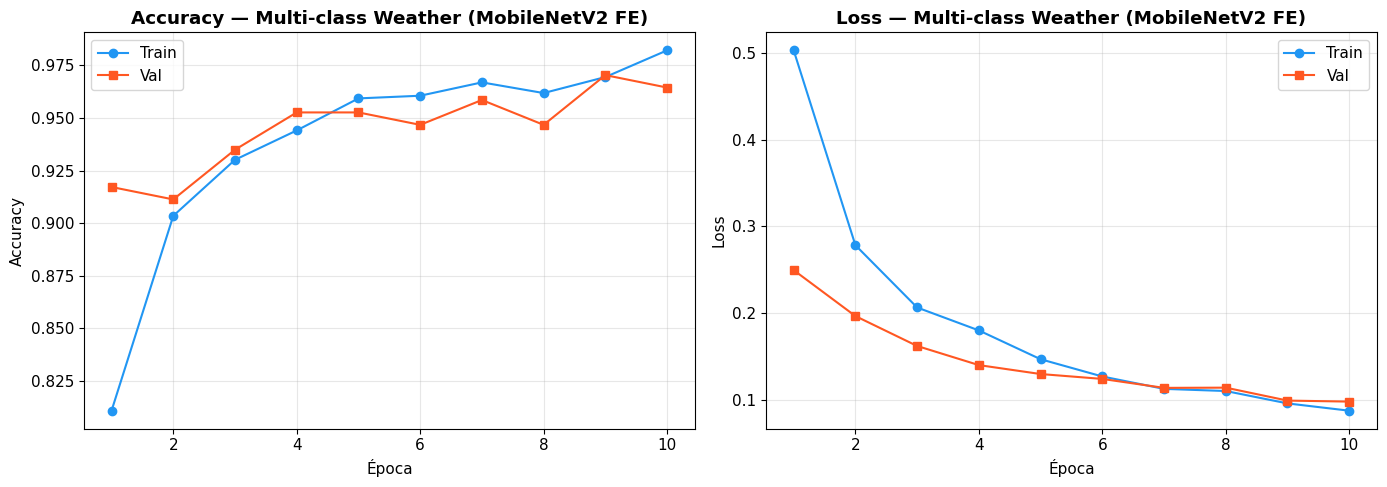

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep = range(1, len(history_1.history['accuracy']) + 1)

axes[0].plot(ep, history_1.history['accuracy'], 'o-', label='Train', color='#2196F3')
axes[0].plot(ep, history_1.history['val_accuracy'], 's-', label='Val', color='#FF5722')
axes[0].set_title(f'Accuracy — {DATASET_LABEL} (MobileNetV2 FE)', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep, history_1.history['loss'], 'o-', label='Train', color='#2196F3')
axes[1].plot(ep, history_1.history['val_loss'], 's-', label='Val', color='#FF5722')
axes[1].set_title(f'Loss — {DATASET_LABEL} (MobileNetV2 FE)', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.5. Predicciones visuales

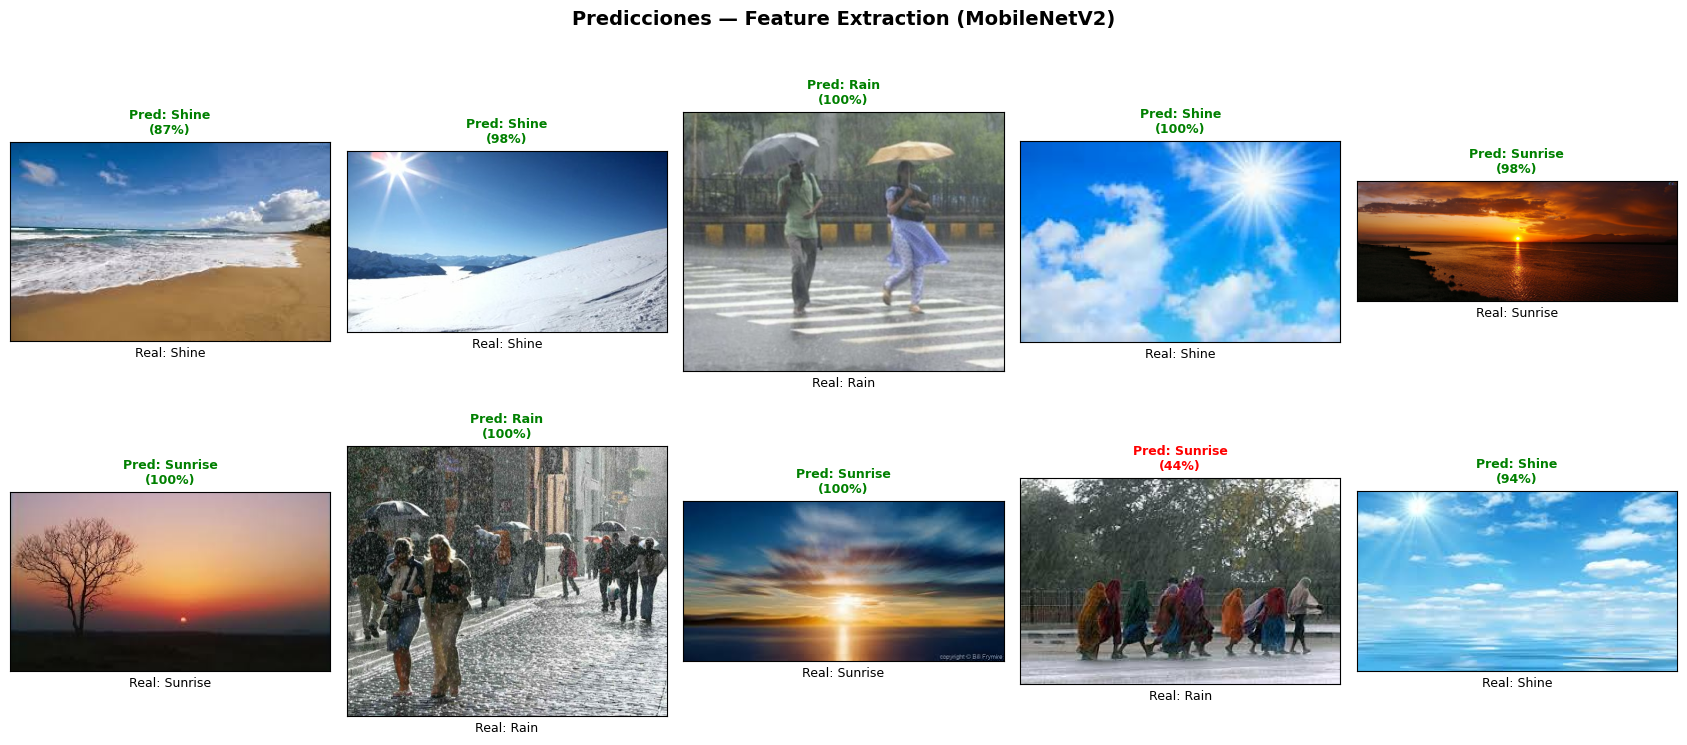

In [11]:
samples = list(test_raw.shuffle(500, seed=SEED).take(10))
batch = tf.stack([tf.image.resize(img, IMG_SIZE) for img, _ in samples])
batch = tf.keras.applications.mobilenet_v2.preprocess_input(batch)
preds = model_1.predict(batch, verbose=0)

fig, axes = plt.subplots(2, 5, figsize=(17, 8))
for i, (img, label) in enumerate(samples):
    ax = axes[i // 5, i % 5]
    pred_class = CLASS_NAMES[np.argmax(preds[i])]
    true_class = CLASS_NAMES[label.numpy()]
    ok = pred_class == true_class
    ax.imshow(img.numpy())
    ax.set_title(f"Pred: {pred_class}\n({preds[i].max():.0%})", fontsize=9,
                 color='green' if ok else 'red', fontweight='bold')
    ax.set_xlabel(f"Real: {true_class}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Predicciones — Feature Extraction (MobileNetV2)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [12]:
t, tr = count_params(model_1)
print("=" * 58)
print("✅ CONCLUSIÓN EJERCICIO 1")
print("=" * 58)
print(f"Dataset ............ {DATASET_LABEL} ({NUM_CLASSES} clases)")
print(f"Modelo base ........ MobileNetV2 ({base_model_1.count_params():,} params congelados)")
print(f"Params entrenados .. {tr:,} ({tr/t*100:.2f}%)")
print(f"Épocas ejecutadas .. {len(history_1.history['accuracy'])}")
print(f"Mejor Val Accuracy . {max(history_1.history['val_accuracy']):.4f}")
print(f"Test Accuracy ...... {test_acc_1:.4f}")
print("=" * 58)

✅ CONCLUSIÓN EJERCICIO 1
Dataset ............ Multi-class Weather (4 clases)
Modelo base ........ MobileNetV2 (2,257,984 params congelados)
Params entrenados .. 5,124 (0.23%)
Épocas ejecutadas .. 10
Mejor Val Accuracy . 0.9704
Test Accuracy ...... 0.9467


---
# 🟡 Ejercicio 2 — Intermedio: EfficientNetB0

**Objetivo:** Feature Extraction con un EDA detallado, **Data Augmentation**, un clasificador más robusto, métricas avanzadas (matriz de confusión y classification report) y visualización de **feature maps**.

**¿Por qué EfficientNetB0?** Mejor balance accuracy/eficiencia de su generación; es un "upgrade" natural sobre MobileNetV2.

**Dataset:** [Fruit and Vegetable Image Recognition](https://www.kaggle.com/datasets/kritikseth/fruit-and-vegetable-image-recognition) — 36 clases, con pocas imágenes por clase: por eso el Data Augmentation y un clasificador más robusto ayudan.

### 2.1. Cargar el dataset y EDA — Análisis exploratorio de los datos

In [13]:
# Cargar Fruit and Vegetable Image Recognition desde Kaggle (36 clases)
DATASET_2 = dict(name='Fruit and Vegetable', source='kaggle',
                 handle='kritikseth/fruit-and-vegetable-image-recognition', path=None, subfolder=None)
use_dataset(DATASET_2, 2)

Using Colab cache for faster access to the 'fruit-and-vegetable-image-recognition' dataset.
⬇️ Dataset de Kaggle listo: kritikseth/fruit-and-vegetable-image-recognition
📂 Contenido: ['test', 'train', 'validation']
🔎 Estructura detectada: ya viene separado en train/val/test
📦 Dataset: Fruit and Vegetable
🏷️ Clases (36): ['apple', 'banana', 'beetroot', 'bell pepper', 'cabbage', 'capsicum', 'carrot', 'cauliflower', 'chilli pepper', 'corn', 'cucumber', 'eggplant', 'garlic', 'ginger', 'grapes', 'jalepeno', 'kiwi', 'lemon', 'lettuce', 'mango', '...']
📊 Train: 3,115 | Val: 351 | Test: 359


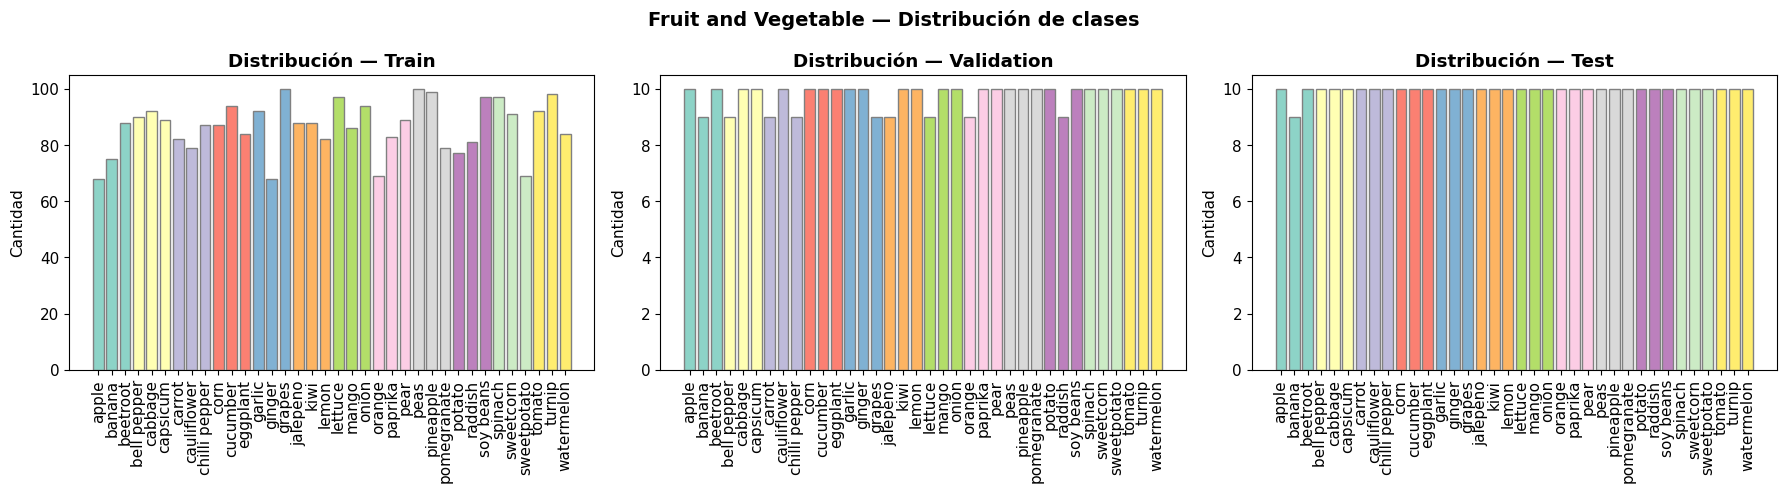

⚖️ Razón clase mayoritaria / minoritaria (train): 1.47  (balanceado)


In [14]:
# Distribución de clases en train / val / test
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, labs, title_str in [(axes[0], lab_train, 'Train'),
                            (axes[1], lab_val, 'Validation'),
                            (axes[2], lab_test, 'Test')]:
    unique, counts = np.unique(labs, return_counts=True)
    colors = plt.cm.Set3(np.linspace(0, 1, NUM_CLASSES))
    bars = ax.bar([CLASS_NAMES[u] for u in unique], counts, color=colors, edgecolor='gray')
    ax.set_title(f'Distribución — {title_str}', fontweight='bold')
    ax.set_ylabel('Cantidad')
    if NUM_CLASSES <= 15:
        for bar, c in zip(bars, counts):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, str(c),
                    ha='center', fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', rotation=30 if NUM_CLASSES <= 10 else 90)
plt.suptitle(f'{DATASET_LABEL} — Distribución de clases', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Balance de clases
ratio = np.bincount(lab_train).max() / np.bincount(lab_train).min()
print(f"⚖️ Razón clase mayoritaria / minoritaria (train): {ratio:.2f}  "
      f"({'balanceado' if ratio < 1.5 else 'desbalanceado — fíjate en precision/recall por clase'})")

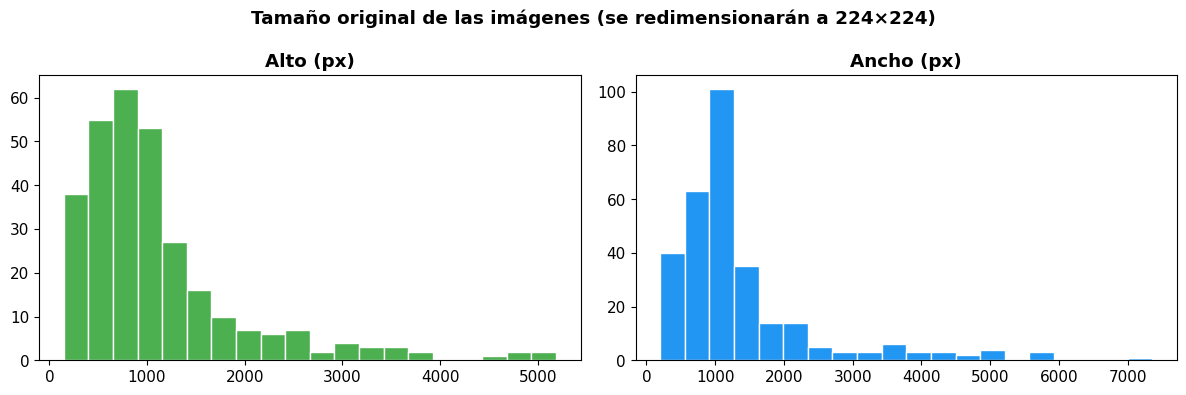

📐 Alto  — min: 147, max: 5184, media: 1117
📐 Ancho — min: 200, max: 7360, media: 1354


In [15]:
# Tamaños originales de las imágenes (muestra de 300)
sizes = np.array([(img.shape[0], img.shape[1]) for img, _ in train_raw.take(300)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(sizes[:, 0], bins=20, color='#4CAF50', edgecolor='white'); axes[0].set_title('Alto (px)', fontweight='bold')
axes[1].hist(sizes[:, 1], bins=20, color='#2196F3', edgecolor='white'); axes[1].set_title('Ancho (px)', fontweight='bold')
plt.suptitle('Tamaño original de las imágenes (se redimensionarán a 224×224)', fontweight='bold')
plt.tight_layout()
plt.show()
print(f"📐 Alto  — min: {sizes[:,0].min()}, max: {sizes[:,0].max()}, media: {sizes[:,0].mean():.0f}")
print(f"📐 Ancho — min: {sizes[:,1].min()}, max: {sizes[:,1].max()}, media: {sizes[:,1].mean():.0f}")

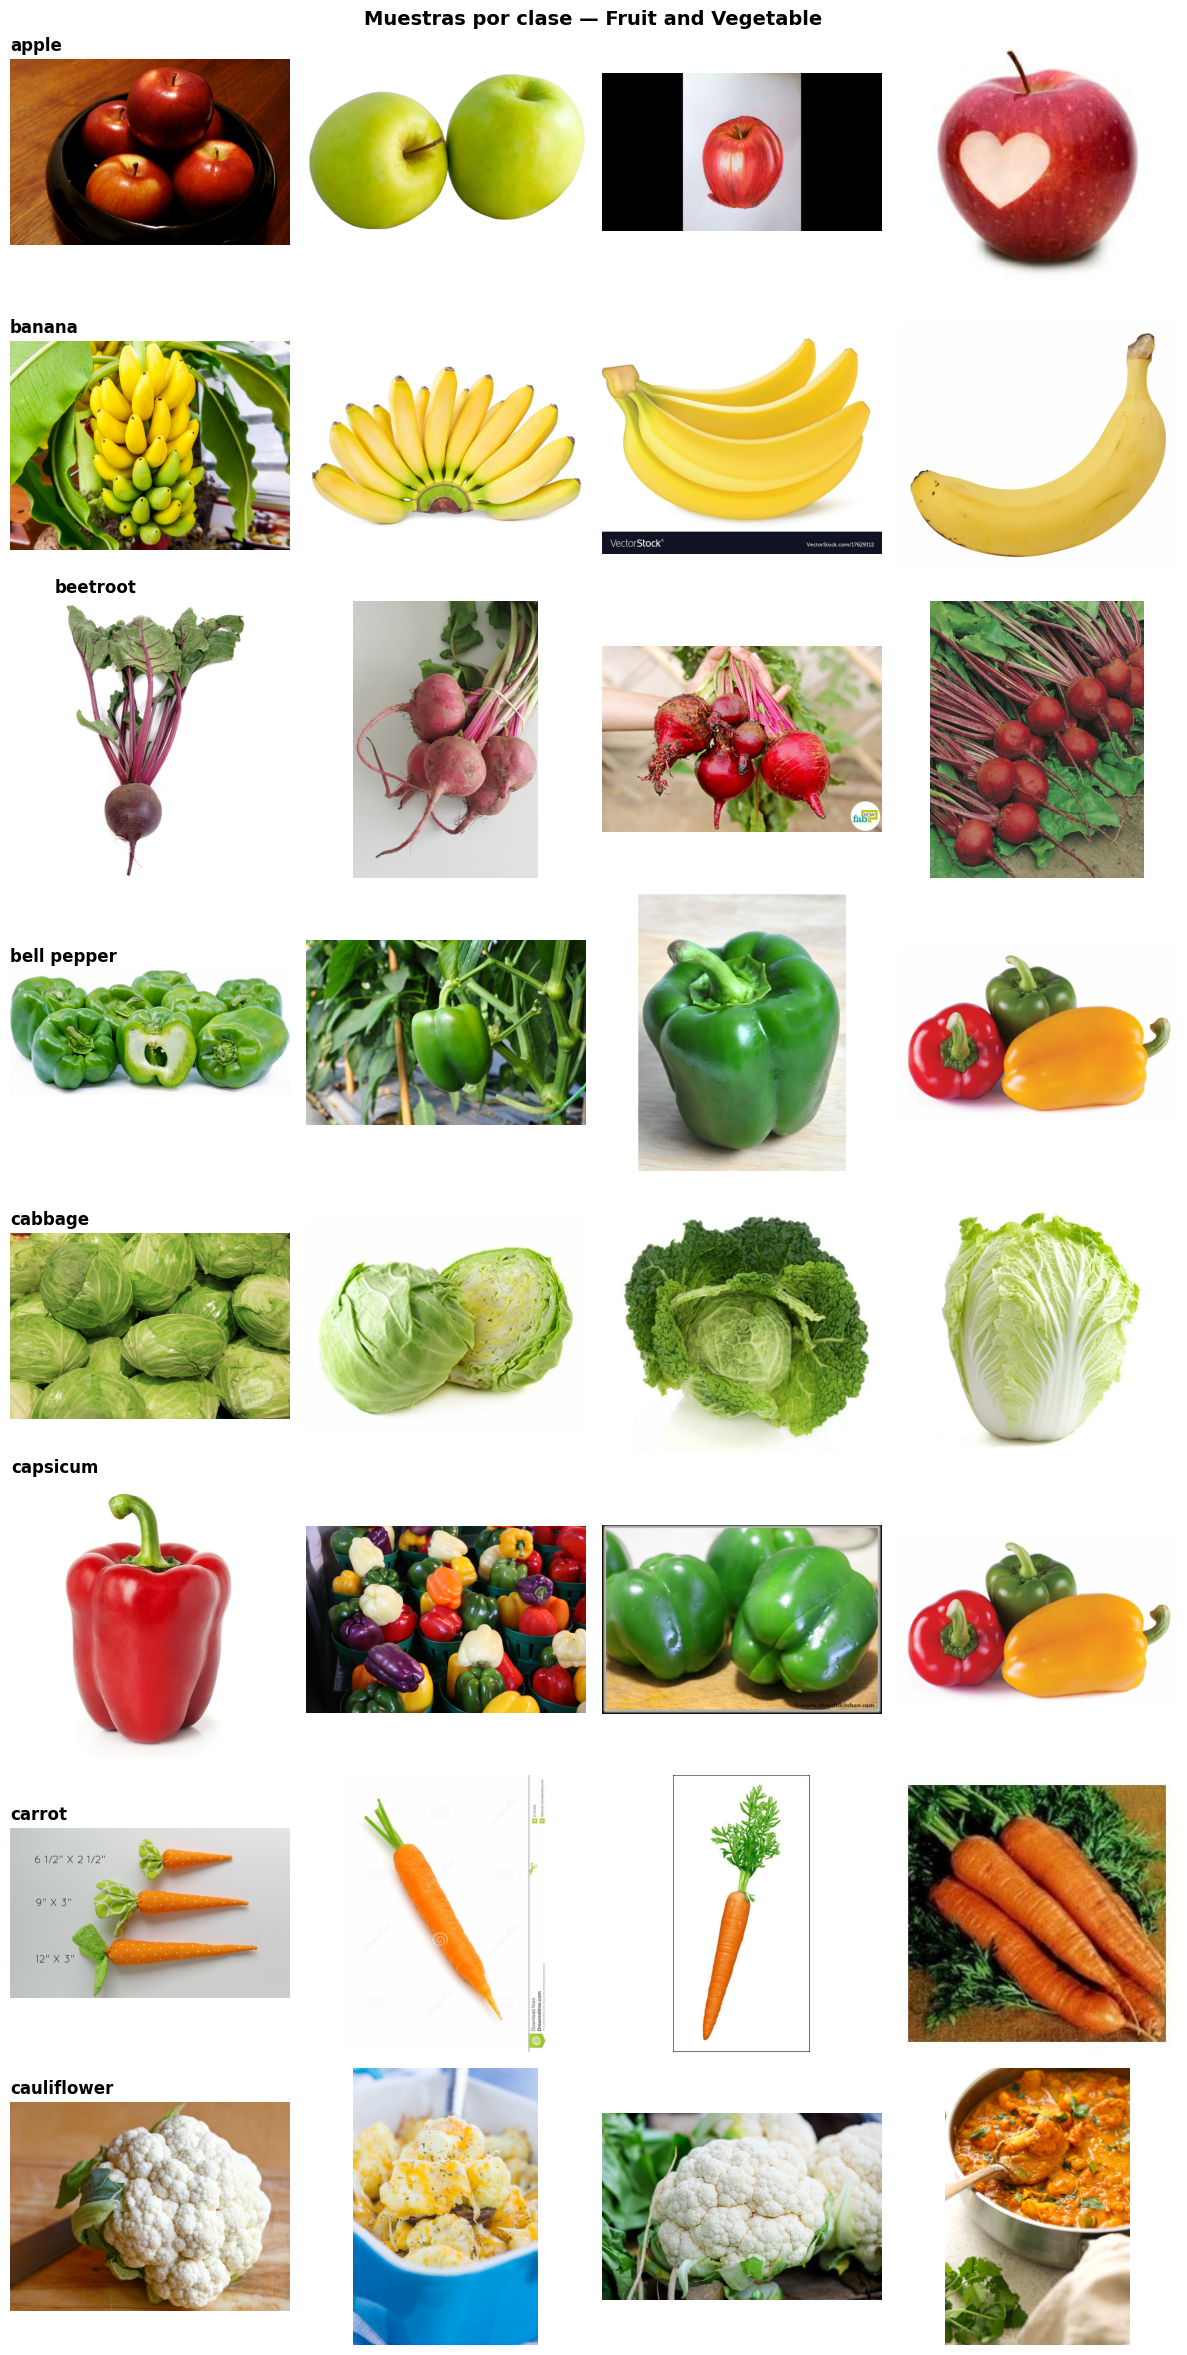

In [16]:
# Muestras por clase (4 por clase)
SHOW = min(NUM_CLASSES, 8)          # máximo 8 clases en la figura
per_class = {i: [] for i in range(SHOW)}
for img, lab in train_raw.shuffle(1000, seed=SEED):
    l = int(lab.numpy())
    if l in per_class and len(per_class[l]) < 4:
        per_class[l].append(img.numpy())
    if all(len(v) >= 4 for v in per_class.values()):
        break

fig, axes = plt.subplots(SHOW, 4, figsize=(12, 3 * SHOW), squeeze=False)
for ci in range(SHOW):
    for col in range(4):
        ax = axes[ci, col]
        if col < len(per_class[ci]):
            ax.imshow(per_class[ci][col])
        ax.axis('off')
        if col == 0:
            ax.set_title(CLASS_NAMES[ci], fontsize=12, fontweight='bold', loc='left')
plt.suptitle(f'Muestras por clase — {DATASET_LABEL}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.2. Preprocesamiento con Data Augmentation

El *augmentation* se aplica **solo al entrenamiento** (las capas aleatorias se desactivan solas en validación/test). Lo colocamos **dentro del modelo**, así funciona igual en cualquier versión de Keras.

> ℹ️ `EfficientNetB0` de Keras ya incluye su normalización interna, por eso le entregamos los píxeles en `[0, 255]`.

In [18]:
def to_float_resized(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)            # [0, 255]
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

train_ds_2 = (train_raw.map(to_float_resized, num_parallel_calls=tf.data.AUTOTUNE)
              .shuffle(1000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds_2 = (val_raw.map(to_float_resized, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
test_ds_2 = (test_raw.map(to_float_resized, num_parallel_calls=tf.data.AUTOTUNE)
             .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name='augmentation')

print("✅ Pipelines listos (augmentation se aplicará dentro del modelo)")

✅ Pipelines listos (augmentation se aplicará dentro del modelo)


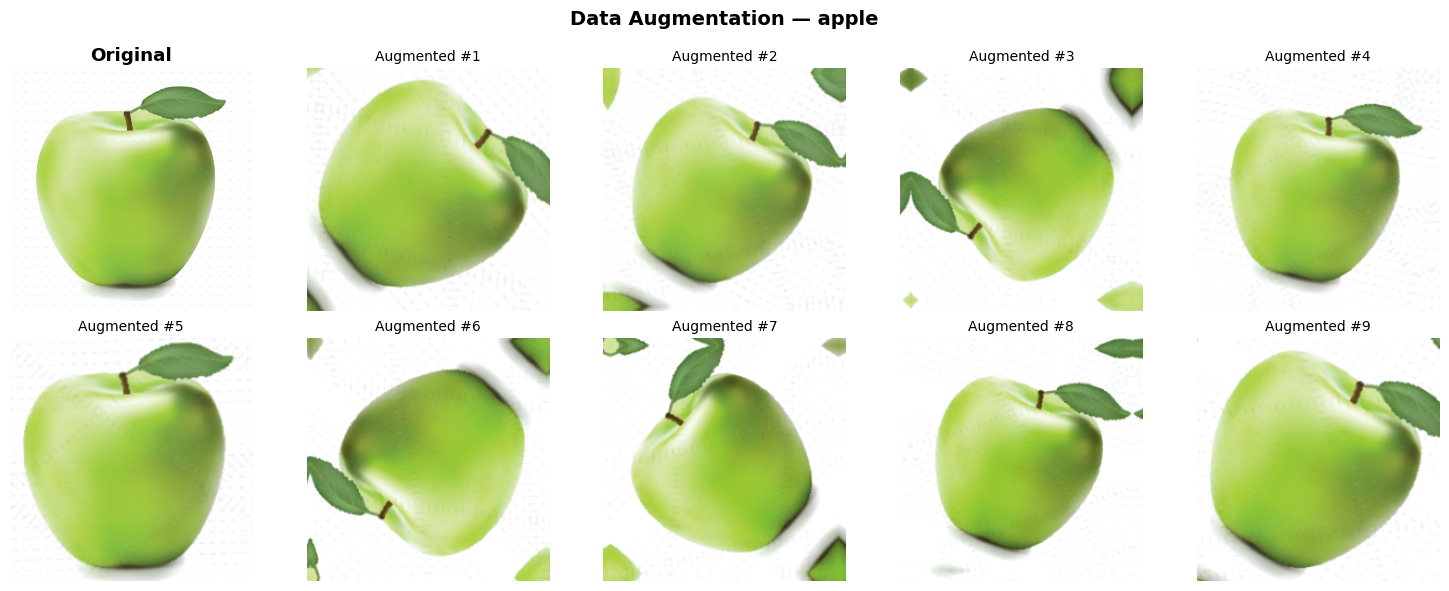

In [19]:
# Visualizar el efecto del augmentation
sample_img, sample_label = next(iter(train_raw))
sample_resized = tf.cast(tf.image.resize(sample_img, IMG_SIZE), tf.float32)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes[0, 0].imshow(sample_img.numpy()); axes[0, 0].set_title('Original', fontweight='bold'); axes[0, 0].axis('off')
for i in range(1, 10):
    ax = axes[i // 5, i % 5]
    aug = data_augmentation(tf.expand_dims(sample_resized, 0), training=True)
    ax.imshow(np.clip(aug[0].numpy(), 0, 255).astype('uint8'))
    ax.set_title(f'Augmented #{i}', fontsize=10); ax.axis('off')
plt.suptitle(f'Data Augmentation — {CLASS_NAMES[sample_label.numpy()]}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.3. Construir el modelo con EfficientNetB0

In [20]:
base_model_2 = tf.keras.applications.EfficientNetB0(
    weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3))
base_model_2.trainable = False

inputs_2 = layers.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs_2)                 # solo actúa en entrenamiento
x = base_model_2(x, training=False)             # BatchNorm en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs_2 = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model_2 = models.Model(inputs_2, outputs_2, name='efficientnetb0_FE')

total, trainable = count_params(model_2)
print("📐 EfficientNetB0 — Feature Extraction")
print(f"🔢 Total: {total:,} | 🔓 Entrenables: {trainable:,} | 🔒 Congelados: {total-trainable:,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
📐 EfficientNetB0 — Feature Extraction
🔢 Total: 4,223,303 | 🔓 Entrenables: 171,172 | 🔒 Congelados: 4,052,131


### 2.4. Entrenar con callbacks

In [21]:
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_2 = model_2.fit(
    train_ds_2,
    validation_data=val_ds_2,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2,
                                             min_lr=1e-6, verbose=1),
    ]
)
print(f"\n🏆 Mejor val_accuracy: {max(history_2.history['val_accuracy']):.4f}")

test_loss_2, test_acc_2 = model_2.evaluate(test_ds_2, verbose=0)
print(f"🧪 Test accuracy: {test_acc_2:.4f}")

Epoch 1/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 103s 695ms/step - accuracy: 0.4132 - loss: 2.6826 - val_accuracy: 0.7151 - val_loss: 1.2933 - learning_rate: 0.0010
Epoch 2/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 72s 548ms/step - accuracy: 0.6478 - loss: 1.2421 - val_accuracy: 0.7806 - val_loss: 0.6629 - learning_rate: 0.0010
Epoch 3/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 82s 659ms/step - accuracy: 0.7043 - loss: 0.9683 - val_accuracy: 0.8405 - val_loss: 0.4611 - learning_rate: 0.0010
Epoch 4/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 69s 533ms/step - accuracy: 0.7557 - loss: 0.7987 - val_accuracy: 0.8746 - val_loss: 0.3622 - learning_rate: 0.0010
Epoch 5/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 83s 666ms/step - accuracy: 0.7734 - loss: 0.7340 - val_accuracy: 0.8632 - val_loss: 0.3361 - learning_rate: 0.0010
Epoch 6/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 142s 670ms/step - accuracy: 0.8016 - loss: 0.6162 - val_accuracy: 0.8917 - val_loss: 0.3519 - learning_rate: 0.0010
Epoch 7/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 71s 544ms/step - accuracy: 0.7920 - loss: 

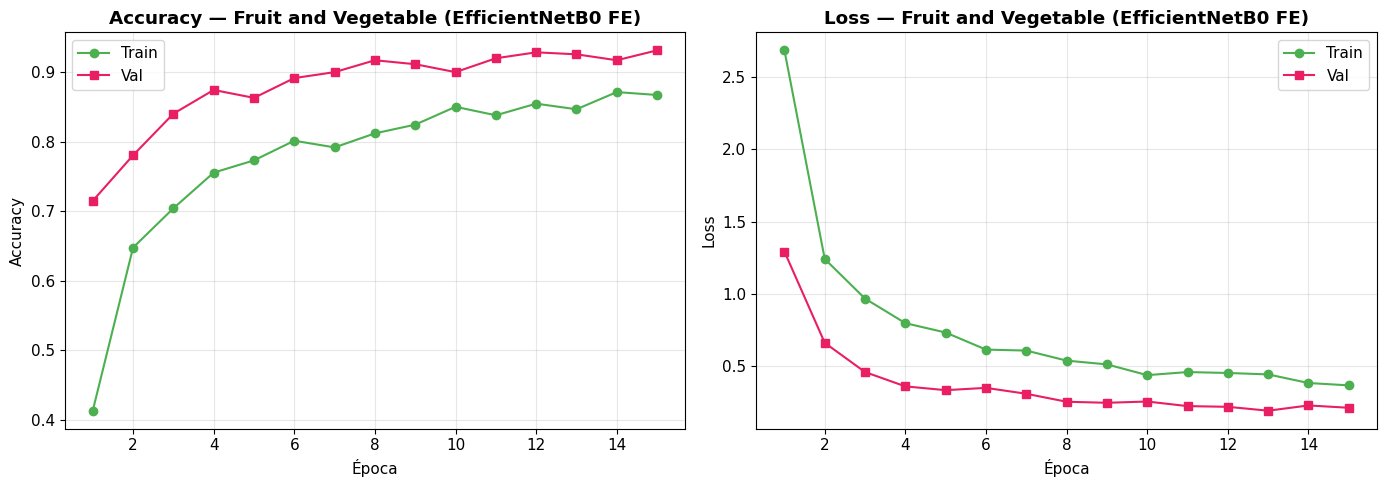

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep = range(1, len(history_2.history['accuracy']) + 1)

axes[0].plot(ep, history_2.history['accuracy'], 'o-', label='Train', color='#4CAF50')
axes[0].plot(ep, history_2.history['val_accuracy'], 's-', label='Val', color='#E91E63')
axes[0].set_title(f'Accuracy — {DATASET_LABEL} (EfficientNetB0 FE)', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep, history_2.history['loss'], 'o-', label='Train', color='#4CAF50')
axes[1].plot(ep, history_2.history['val_loss'], 's-', label='Val', color='#E91E63')
axes[1].set_title(f'Loss — {DATASET_LABEL} (EfficientNetB0 FE)', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.5. Evaluación detallada: Classification Report + Confusion Matrix (sobre TEST)

In [23]:
from sklearn.metrics import classification_report, confusion_matrix

y_true, y_pred = [], []
for images, lbls in test_ds_2:
    p = model_2.predict(images, verbose=0)
    y_pred.extend(np.argmax(p, axis=1))
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
y_true, y_pred = np.array(y_true), np.array(y_pred)

print(f"📊 Classification Report — {DATASET_LABEL} (EfficientNetB0 FE, conjunto TEST)")
print("=" * 70)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

📊 Classification Report — Fruit and Vegetable (EfficientNetB0 FE, conjunto TEST)
               precision    recall  f1-score   support

        apple     1.0000    0.8000    0.8889        10
       banana     1.0000    0.7778    0.8750         9
     beetroot     1.0000    1.0000    1.0000        10
  bell pepper     0.6154    0.8000    0.6957        10
      cabbage     1.0000    1.0000    1.0000        10
     capsicum     0.8000    0.4000    0.5333        10
       carrot     1.0000    0.9000    0.9474        10
  cauliflower     1.0000    1.0000    1.0000        10
chilli pepper     1.0000    0.8000    0.8889        10
         corn     0.0000    0.0000    0.0000        10
     cucumber     1.0000    1.0000    1.0000        10
     eggplant     1.0000    1.0000    1.0000        10
       garlic     1.0000    1.0000    1.0000        10
       ginger     1.0000    1.0000    1.0000        10
       grapes     1.0000    1.0000    1.0000        10
     jalepeno     0.8333    1.0000    

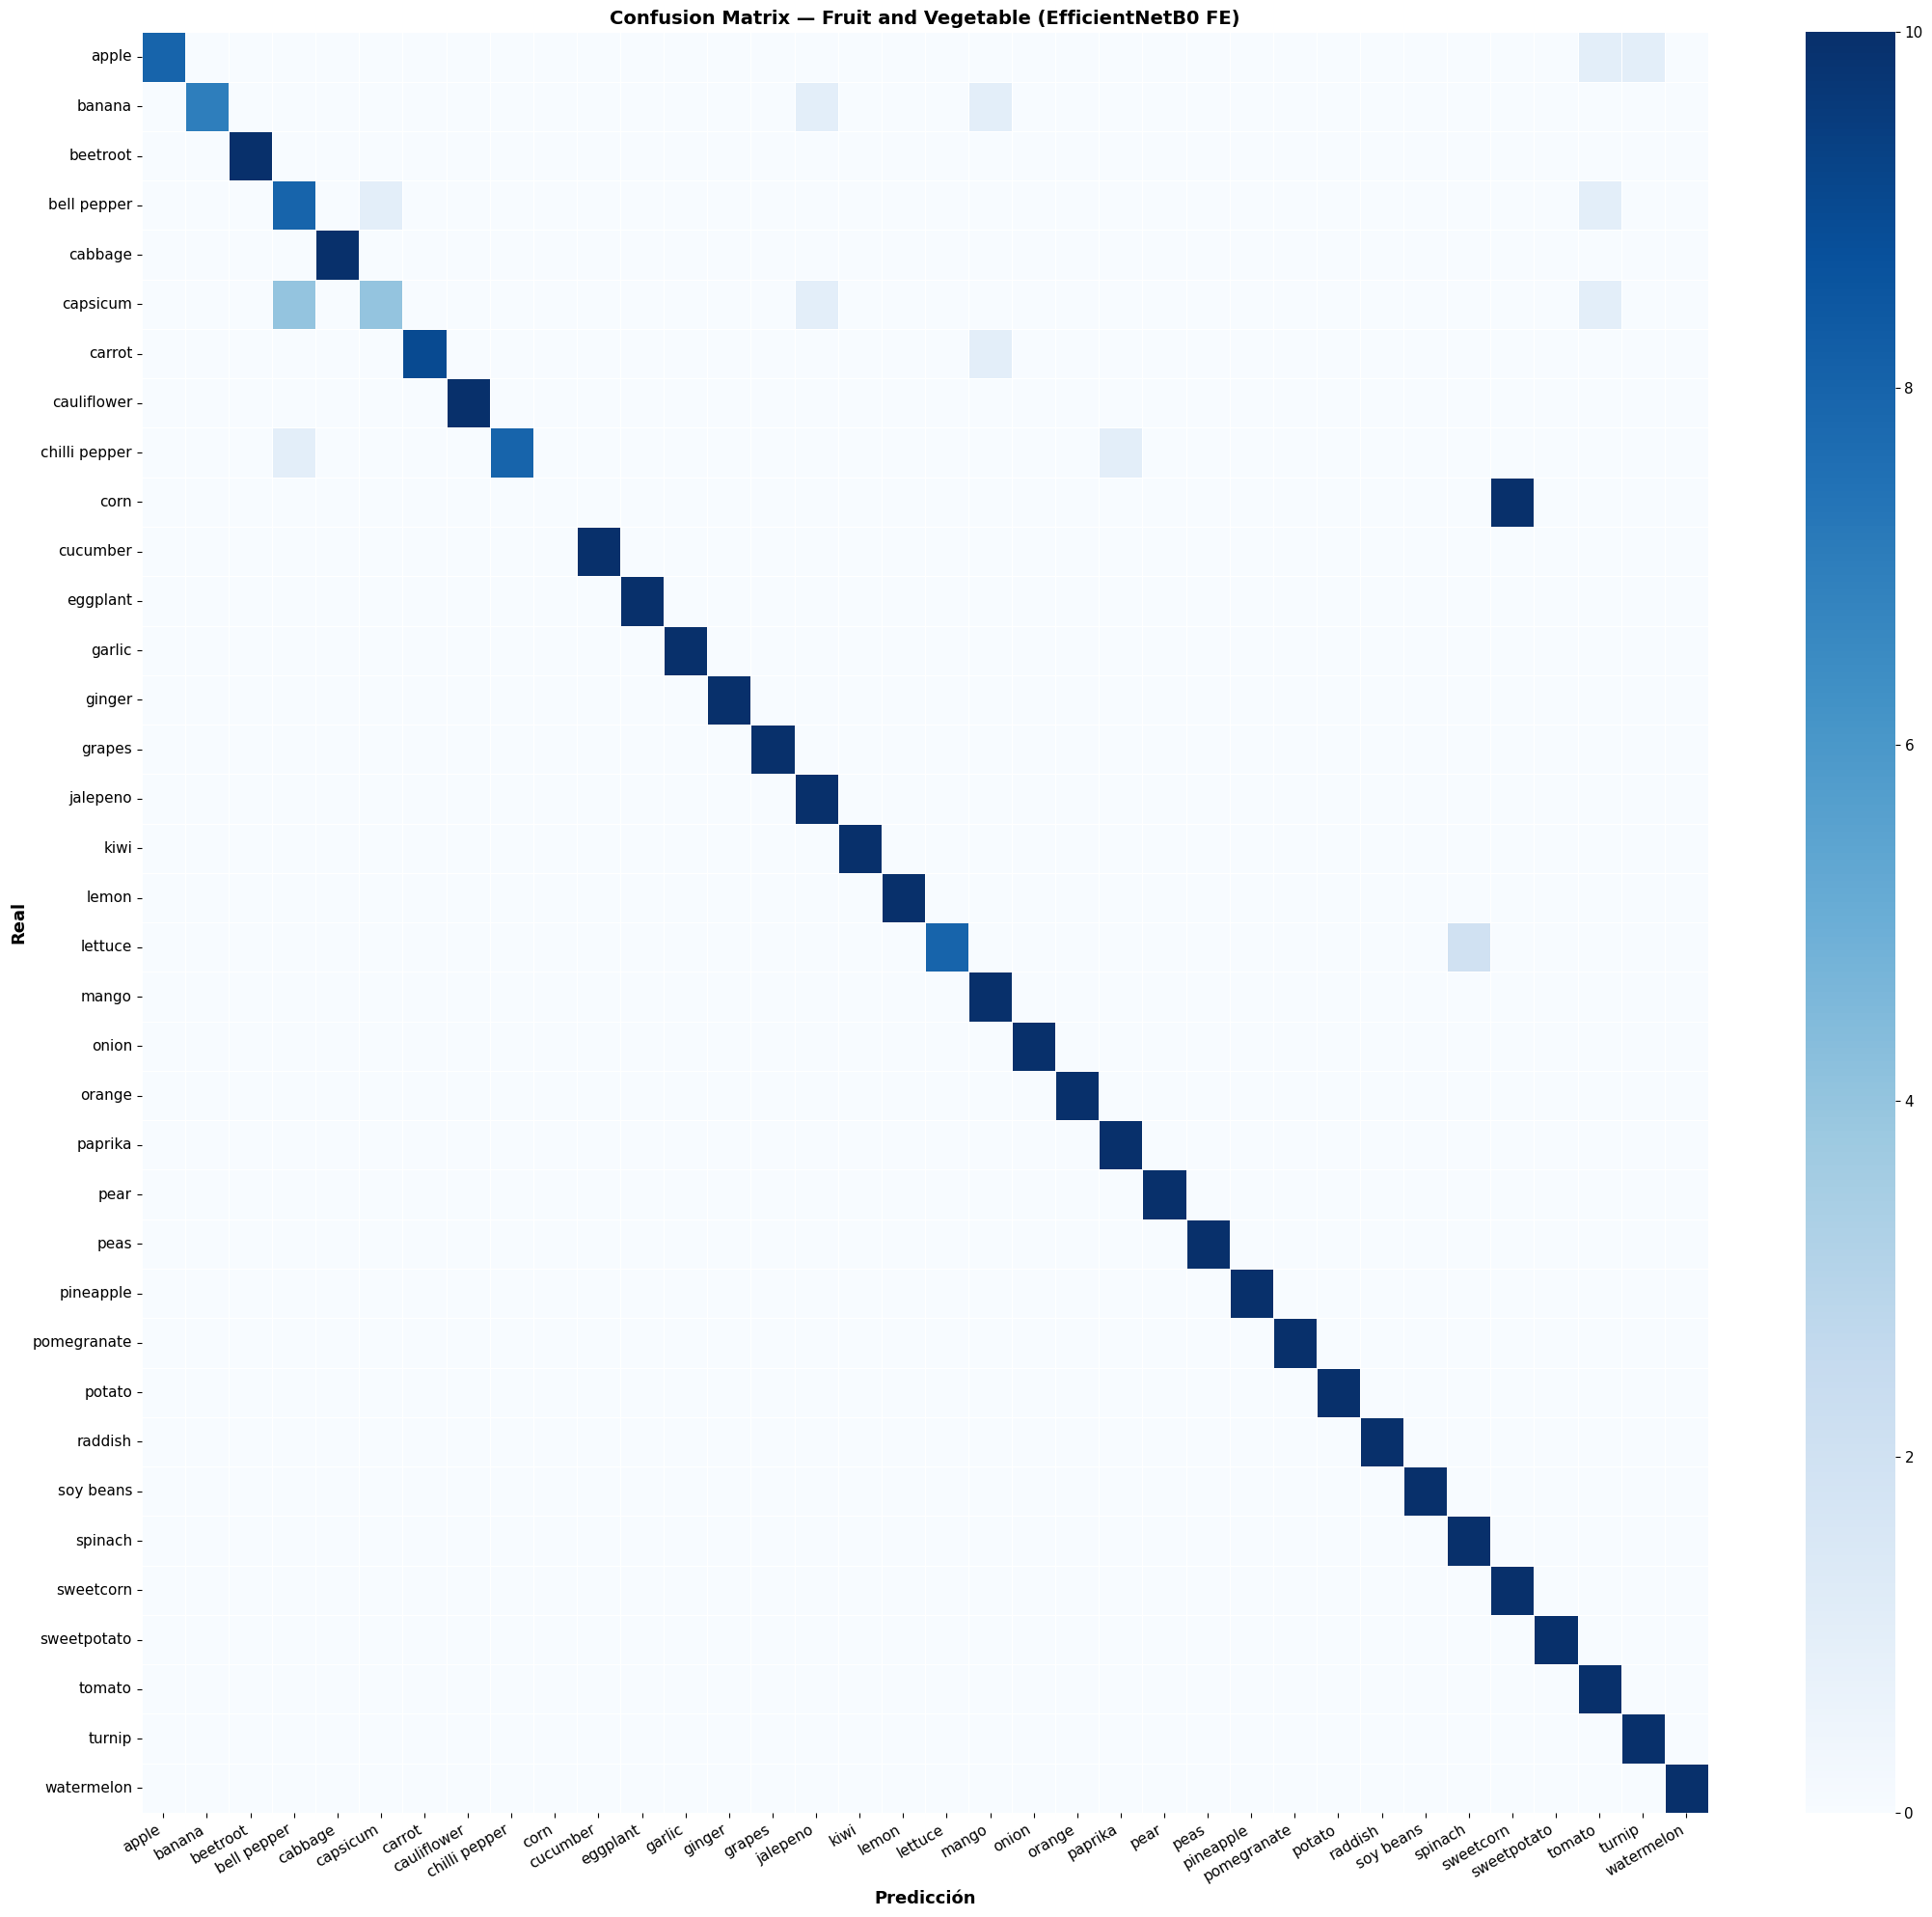


🔍 Principales confusiones (real → predicho):
   corn → sweetcorn: 10 errores
   capsicum → bell pepper: 4 errores
   lettuce → spinach: 2 errores
   chilli pepper → paprika: 1 errores
   chilli pepper → bell pepper: 1 errores


In [24]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(min(22, max(6, NUM_CLASSES * 1.4)), min(20, max(5, NUM_CLASSES * 1.2))))
sns.heatmap(cm, annot=(NUM_CLASSES <= 15), fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax,
            linewidths=0.5, linecolor='white', annot_kws={'size': 13, 'fontweight': 'bold'})
ax.set_xlabel('Predicción', fontsize=13, fontweight='bold')
ax.set_ylabel('Real', fontsize=13, fontweight='bold')
ax.set_title(f'Confusion Matrix — {DATASET_LABEL} (EfficientNetB0 FE)', fontsize=14, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# Principales confusiones
errors = [(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j])
          for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
errors.sort(reverse=True)
print("\n🔍 Principales confusiones (real → predicho):")
if errors:
    for n, a, b in errors[:5]:
        print(f"   {a} → {b}: {n} errores")
else:
    print("   ¡Ninguna! El modelo acertó todo el conjunto de test.")

### 2.6. Visualización de Feature Maps

¿Qué "ve" el backbone EfficientNetB0? Extraemos los mapas de activación de capas de distinta profundidad.

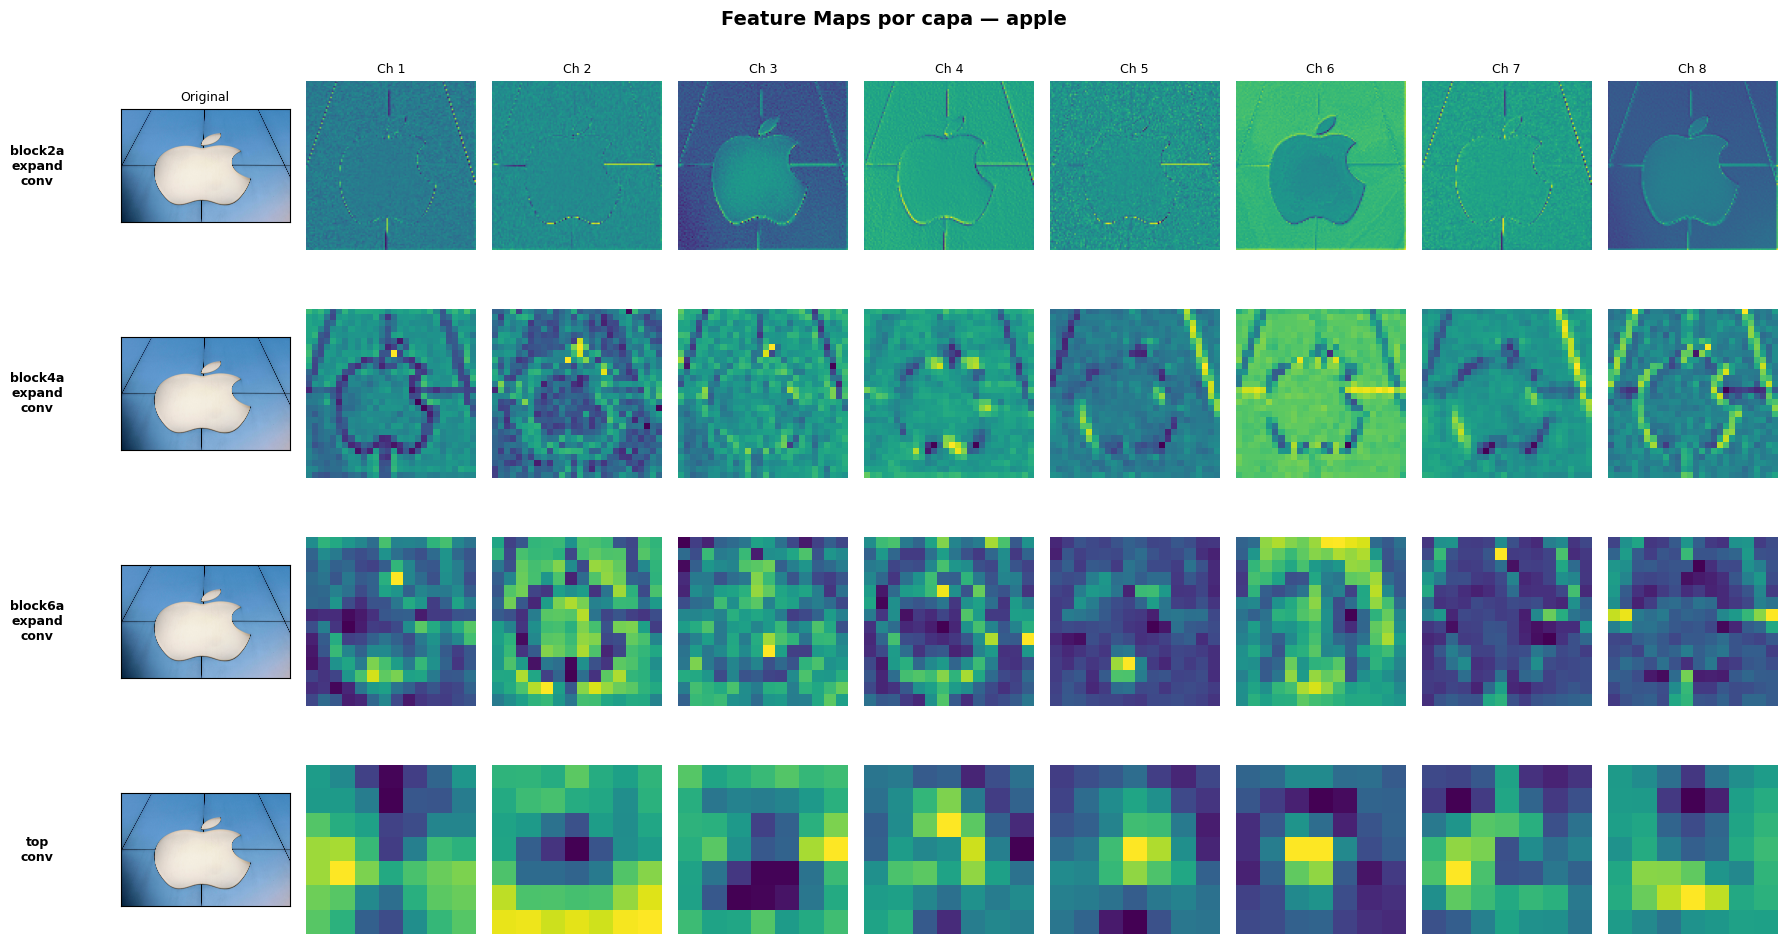

In [25]:
layer_names = ['block2a_expand_conv', 'block4a_expand_conv', 'block6a_expand_conv', 'top_conv']
feature_models = [models.Model(inputs=base_model_2.input,
                               outputs=base_model_2.get_layer(n).output) for n in layer_names]

img_raw, lab_raw = next(iter(test_raw))
img_in = tf.expand_dims(tf.cast(tf.image.resize(img_raw, IMG_SIZE), tf.float32), 0)

fig, axes = plt.subplots(len(layer_names), 9, figsize=(18, 2.5 * len(layer_names)))
for row, (fm, lname) in enumerate(zip(feature_models, layer_names)):
    feats = fm.predict(img_in, verbose=0)
    axes[row, 0].imshow(img_raw.numpy())
    axes[row, 0].set_title('Original' if row == 0 else '', fontsize=9)
    axes[row, 0].set_ylabel(lname.replace('_', '\n'), fontsize=9, fontweight='bold',
                            rotation=0, labelpad=60, va='center')
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    for col in range(1, 9):
        ax = axes[row, col]
        if col - 1 < feats.shape[-1]:
            ax.imshow(feats[0, :, :, col - 1], cmap='viridis')
        ax.axis('off')
        if row == 0:
            ax.set_title(f'Ch {col}', fontsize=9)

plt.suptitle(f'Feature Maps por capa — {CLASS_NAMES[lab_raw.numpy()]}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> 📝 **Observa la progresión:** las capas tempranas detectan bordes y texturas, las intermedias patrones más complejos y las profundas abstracciones de alto nivel. Esos features \"universales\" son los que ImageNet transfiere a tu problema.

In [26]:
t, tr = count_params(model_2)
print("=" * 58)
print("✅ CONCLUSIÓN EJERCICIO 2")
print("=" * 58)
print(f"Dataset ............ {DATASET_LABEL} ({NUM_CLASSES} clases)")
print(f"Modelo base ........ EfficientNetB0 ({base_model_2.count_params():,} params congelados)")
print(f"Params entrenados .. {tr:,} ({tr/t*100:.2f}%)")
print(f"Augmentation ....... Flip + Rotation + Zoom + Contrast")
print(f"Épocas ejecutadas .. {len(history_2.history['accuracy'])}")
print(f"Mejor Val Accuracy . {max(history_2.history['val_accuracy']):.4f}")
print(f"Test Accuracy ...... {test_acc_2:.4f}")
print("=" * 58)

✅ CONCLUSIÓN EJERCICIO 2
Dataset ............ Fruit and Vegetable (36 clases)
Modelo base ........ EfficientNetB0 (4,049,571 params congelados)
Params entrenados .. 171,172 (4.05%)
Augmentation ....... Flip + Rotation + Zoom + Contrast
Épocas ejecutadas .. 15
Mejor Val Accuracy . 0.9316
Test Accuracy ...... 0.9248


---
# 📋 Resumen final de los 2 ejercicios

In [27]:
summary = pd.DataFrame([
    {'Ejercicio': '1 · Básico',     'Dataset': DS_INFO[1]['DATASET_LABEL'], 'Clases': DS_INFO[1]['NUM_CLASSES'],
     'Modelo': 'MobileNetV2',
     'Val Acc': f"{max(history_1.history['val_accuracy']):.4f}", 'Test Acc': f"{test_acc_1:.4f}"},
    {'Ejercicio': '2 · Intermedio', 'Dataset': DS_INFO[2]['DATASET_LABEL'], 'Clases': DS_INFO[2]['NUM_CLASSES'],
     'Modelo': 'EfficientNetB0 + augmentation',
     'Val Acc': f"{max(history_2.history['val_accuracy']):.4f}", 'Test Acc': f"{test_acc_2:.4f}"},
])
print(summary.to_string(index=False))

     Ejercicio             Dataset  Clases                        Modelo Val Acc Test Acc
    1 · Básico Multi-class Weather       4                   MobileNetV2  0.9704   0.9467
2 · Intermedio Fruit and Vegetable      36 EfficientNetB0 + augmentation  0.9316   0.9248


| Concepto | Descripción |
|----------|-------------|
| **Transfer Learning** | Reutilizar el conocimiento de ImageNet para nuestro problema |
| **Feature Extraction** | Congelar el backbone y entrenar solo el clasificador nuevo |
| **`include_top=False`** | Elimina las capas Dense originales de 1000 clases |
| **`trainable = False`** | Congela los pesos del backbone |
| **`preprocess_input`** | Cada modelo tiene su propia normalización |
| **`training=False`** | Las capas BatchNorm del backbone usan estadísticos de ImageNet |
| **Val vs Test** | Val sirve para ajustar/parar el entrenamiento; Test da la métrica final honesta |

**Siguiente paso natural:** *Fine-Tuning* — descongelar las últimas capas del backbone y re-entrenarlas con un learning rate muy bajo para adaptar los features a tu dominio.